# Capacity Limits: Capacity, Commissioning and Shared Potentials

The component notebooks have used several parameters that limit the capacity of a component: `capacityMax` for the potentials of wind turbines and PV, `capacityMin` for an expansion target, `capacityFix` for existing plants and `commissioningFix` for planned cables. This notebook puts them into order and adds two new ones:

| New parameter | What it does |
|---|---|
| `commissioningMax` | limits how much capacity can be newly built in an investment period, e.g. because of limited supply chains |
| `sharedPotentialID` | lets several components share one potential, e.g. the same land |

All parameters of this notebook belong to every component type (sources, sinks, conversions, storages and transmissions).

## 1. Capacity and commissioning

FINE distinguishes two quantities in every investment period:

- The **capacity** is everything that is available in a period: the capacity built in this period and in earlier ones that has not yet reached the end of its technical lifetime, plus existing capacity (`stockCommissioning`).
- The **commissioning** is only the capacity newly built in that period.

Both can be limited from below, from above, or fixed:

| | Minimum | Maximum | Fixed |
|---|---|---|---|
| **Capacity** (everything available) | `capacityMin`, e.g. an expansion target ([Sources](11_sources.ipynb)) | `capacityMax`, e.g. a potential ([Basic Tutorial](01_basic_tutorial.ipynb)) | `capacityFix`, e.g. existing plants ([Sources](11_sources.ipynb), [Storages](14_storages.ipynb)) |
| **Commissioning** (newly built) | `commissioningMin` | `commissioningMax`, e.g. a maximum building rate (this notebook) | `commissioningFix`, e.g. planned projects ([Transmissions](15_transmissions.ipynb)) |

All six accept the same types of input: a single number (the same for all regions and periods), a `pd.Series` with one value per region (the same for all periods), or a dictionary with the investment periods as keys and one of the two as values. A dictionary has to contain every investment period.

Where a component may be built at all is set with `locationalEligibility`, as shown for the offshore wind turbines in the [Sources notebook](11_sources.ipynb).

## 2. The model of the basic tutorial

We start from the model of the basic tutorial (`tutorialHelpers.py`) and optimize it once without any changes, so that we can compare the results below with it.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn
from tutorialHelpers import (
    COLORS,
    buildBasicTutorialModel,
    plotCapacityAndGeneration,
    readData,
)

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

In [2]:
esM = buildBasicTutorialModel()
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)
costBasic = esM.objectiveValue

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (71 outputs left out)

Solved with barrier


    3402    5.9738972e+05   0.000000e+00   0.000000e+00      1s


Solved in 3402 iterations and 0.75 seconds (0.88 work units)


Optimal objective  5.973897241e+05


The new wind turbines per region and investment period, which is the `commissioning` of the summary:

In [3]:
def newCapacity(esM, component):
    """Return the new capacity (commissioning) of a source per period and region in GW."""
    return pd.DataFrame(
        {
            year: esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=year)
            .loc[(component, "commissioning")]
            .iloc[0]
            for year in esM.investmentPeriodNames
        }
    ).T.astype(float)


newWindBasic = newCapacity(esM, "Wind turbines")
newWindBasic.round(1)

,north,south
2020,82.7,0.0
2030,80.2,0.0
2040,187.7,115.3


## 3. A maximum building rate with `commissioningMax`

Building wind turbines takes time: planning permissions, manufacturers and installers limit how many turbines can be built per year. In the basic tutorial, the model builds almost 190 GW of new wind turbines in the north in the investment period 2040 (this includes replacing the turbines built in 2020).

We now allow at most **100 GW of new wind turbines per region and investment period**. A single number applies to every region and period. Note the difference to `capacityMax`: the potential still limits the total capacity, while `commissioningMax` only limits what is added in one period.

`esM.updateComponent` changes the existing component (see the [Conversions notebook](13_conversions.ipynb)). After a component has been added or changed, the time series have to be aggregated again before optimizing; otherwise `optimize` raises an error.

In [4]:
esM.updateComponent("Wind turbines", {"commissioningMax": 100})  # GW per period
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (73 outputs left out)

Solved with barrier


    2903    6.3820037e+05   0.000000e+00   0.000000e+00      1s


Solved in 2903 iterations and 0.89 seconds (0.88 work units)


Optimal objective  6.382003746e+05


In [5]:
newWindLimited = newCapacity(esM, "Wind turbines")
pd.concat(
    {"Basic tutorial": newWindBasic, "With commissioningMax": newWindLimited}, axis=1
).round(1)

Basic tutorial        With commissioningMax       
              north  south                 north  south
2020           82.7    0.0                  71.8    0.0
2030           80.2    0.0                 100.0   45.3
2040          187.7  115.3                 100.0  100.0

The limit is binding in 2040 in both regions: no more than 100 GW of new wind turbines. The model reacts by building earlier and by using the south more:

- In the north, it builds 100 GW in 2030 instead of 80 GW.
- In the south, it already builds 45 GW in 2030 instead of none, and by 2040 it uses the whole potential of the south (145 GW).
- In 2020, it builds somewhat fewer wind turbines in the north (72 GW instead of 83 GW). Turbines built in 2020 reach the end of their lifetime of 20 years by 2040, so replacing them in 2040 would also count against the limit of that period.

In total, about 345 GW of wind turbines are available in 2040 instead of 383 GW. The gas power plants produce about as much as before, since the CO<sub>2</sub> limit is the same. Building earlier and in less windy places is more expensive:

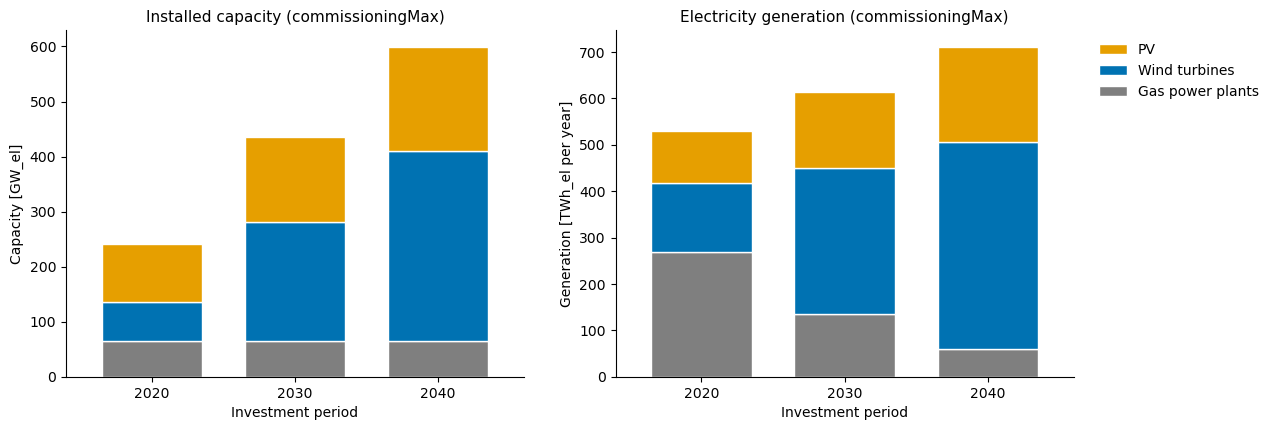

In [6]:
capacity, generation = plotCapacityAndGeneration(
    esM, ["Gas power plants", "Wind turbines", "PV"], title=" (commissioningMax)"
)

In [7]:
f"Additional cost: {(esM.objectiveValue - costBasic) / 1000:.1f} billion Euro"

'Additional cost: 40.8 billion Euro'

## 4. Sharing land with `sharedPotentialID`

Often, several technologies compete for the same potential. Salt caverns can store hydrogen or natural gas, and a roof can carry PV panels or solar thermal collectors. Here, we look at land: so far, the PV potential in our data stands for PV on roofs and other surfaces that wind turbines cannot use. We now add **open-field PV**, which needs land, and assume that it can only be built on the land that is suitable for wind turbines.

**`sharedPotentialID`** links the potentials of components. Components with the same ID must together stay within their `capacityMax` in every region and period:

$$\frac{\text{capacity of the wind turbines}}{\text{capacityMax of the wind turbines}} + \frac{\text{capacity of open-field PV}}{\text{capacityMax of open-field PV}} \le 1$$

The capacity of each component is measured relative to its own potential, so the potentials may be given in different units or for technologies that need very different amounts of land. We assume that the land for 1 GW of wind turbines can carry 3 GW of open-field PV. If the wind turbines use 50 % of their potential in a region, open-field PV can use the other 50 % of its potential there.

Open-field PV has the same capacity factors as the other PV, but is cheaper per GW. Land only becomes scarce if the system needs a lot of wind and solar power, so we build a new model in which no CO<sub>2</sub> may be emitted in 2040 (as in the [Storages notebook](14_storages.ipynb)). The building rate of section 3 does not apply to it.

In [8]:
capacityPotential = readData("capacityPotential.csv")
pvCapacityFactor = readData("pvCapacityFactor.csv")

esM = buildBasicTutorialModel(co2LimitPerPeriod={2020: 90, 2030: 45, 2040: 0})
esM.updateComponent("Wind turbines", {"sharedPotentialID": "land"})

esM.add(
    fn.Source(
        esM=esM,
        name="Open-field PV",
        commodity="electricity",
        hasCapacityVariable=True,
        operationRateMax=pvCapacityFactor,
        capacityMax=3 * capacityPotential.loc["Wind (onshore)"],  # GW
        sharedPotentialID="land",
        investPerCapacity={2020: 600, 2030: 400, 2040: 300},  # million Euro per GW
        opexPerCapacity=10,  # million Euro per GW and year
        interestRate=0.08,
        economicLifetime=25,
    )
)

In [9]:
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (76 outputs left out)

Solved with barrier


    3735    5.5503889e+05   0.000000e+00   0.000000e+00      1s


Solved in 3735 iterations and 0.94 seconds (0.73 work units)


Optimal objective  5.550388860e+05


How much of the land does each technology use? The share is the capacity divided by the potential:

In [10]:
landUse = {}
for year in esM.investmentPeriodNames:
    capacities = (
        esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=year)
        .xs("capacity", level="Property")
        .droplevel("Unit")
    )
    landUse[year, "Wind turbines"] = (
        capacities.loc["Wind turbines"] / capacityPotential.loc["Wind (onshore)"]
    )
    landUse[year, "Open-field PV"] = capacities.loc["Open-field PV"] / (
        3 * capacityPotential.loc["Wind (onshore)"]
    )
landUse = pd.DataFrame(landUse).T.astype(float)
landUse.index.names = ["period", "component"]
(100 * landUse).round(0)  # percent of the land

north  south
period component                  
2020   Wind turbines   24.0    0.0
       Open-field PV    6.0   17.0
2030   Wind turbines   52.0    0.0
       Open-field PV    7.0   46.0
2040   Wind turbines   98.0    0.0
       Open-field PV    2.0  100.0

The land is used differently in the two regions. In the windy north, it goes to wind turbines; open-field PV only takes a small part. In the south, where the wind turbines produce much less, the model only builds open-field PV there. By 2040, when no CO<sub>2</sub> may be emitted, the land is completely used in both regions (100 %): the shared potential is now binding. Without sharedPotentialID, the model could build both technologies up to their full potential on the same land.

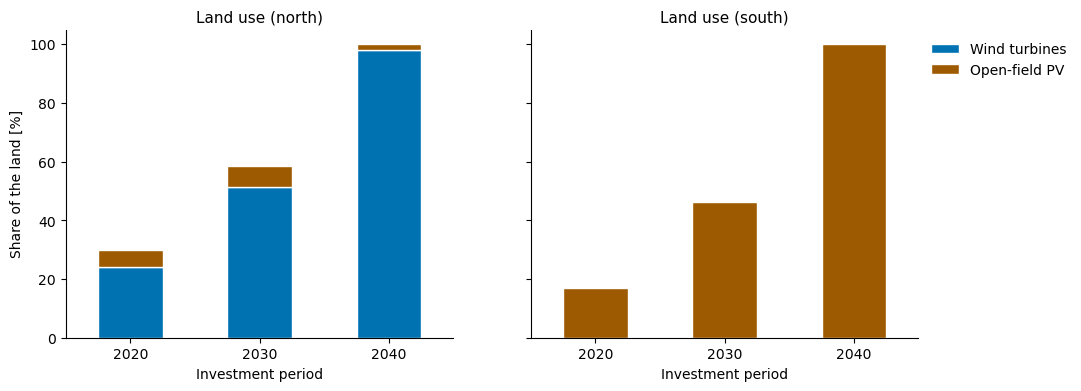

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, region in zip(axes, ["north", "south"]):
    data = (
        100 * landUse[region].unstack("component")[["Wind turbines", "Open-field PV"]]
    )
    data.plot.bar(
        ax=ax,
        stacked=True,
        color=[COLORS["Wind turbines"], COLORS["Open-field PV"]],
        edgecolor="white",
        rot=0,
        legend=region == "south",
        xlabel="Investment period",
        ylabel="Share of the land [%]",
        title=f"Land use ({region})",
    )
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

## Things to try

- Set `commissioningMax` of the wind turbines to 50 GW. Can the model still meet the CO<sub>2</sub> limit?
- Give the wind turbines a minimum building rate with `commissioningMin`, e.g. 20 GW per region and period.
- Assume that the land for 1 GW of wind turbines carries 5 GW of open-field PV instead of 3 GW. How does the land use change?

The next notebook, [Operation Limits](22_operation_limits.ipynb), limits the operation of components instead of their capacity.